<a href="https://colab.research.google.com/github/souvikdey214-code/Krutanic_Weekly-Project-Task/blob/main/04_Paw_Sense.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
print("TensorFlow Version:", tf.__version__)

In [ ]:
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("GPU Available")
    for gpu in gpus:
        print(gpu)
else:
    print("GPU not available. Using CPU.")

In [ ]:
import os

dataset_dir = r"C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs"

train_dir = os.path.join(dataset_dir, "train")
test_dir = os.path.join(dataset_dir, "test")

print("Train directory:", train_dir)
print("Test directory:", test_dir)

Train directory: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\train
Test directory: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test


In [ ]:
required_folders = [
    train_dir,
    test_dir,
    os.path.join(train_dir, "cats"),
    os.path.join(train_dir, "dogs"),
    os.path.join(test_dir, "cats"),
    os.path.join(test_dir, "dogs")
]

for folder in required_folders:
    if os.path.exists(folder):
        print("✓ Found:", folder)
    else:
        print("✗ Missing:", folder)

✓ Found: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\train
✓ Found: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test
✓ Found: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\train\cats
✓ Found: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\train\dogs
✓ Found: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\cats
✓ Found: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\dogs


In [ ]:
train_cats = os.listdir(os.path.join(train_dir, "cats"))
train_dogs = os.listdir(os.path.join(train_dir, "dogs"))

test_cats = os.listdir(os.path.join(test_dir, "cats"))
test_dogs = os.listdir(os.path.join(test_dir, "dogs"))

print("\nDataset Summary")
print("-" * 40)

print("Training Cats :", len(train_cats))
print("Training Dogs :", len(train_dogs))

print("Testing Cats  :", len(test_cats))
print("Testing Dogs  :", len(test_dogs))


Dataset Summary
----------------------------------------
Training Cats : 10000
Training Dogs : 10000
Testing Cats  : 2500
Testing Dogs  : 2500


In [ ]:
print("Dataset Distribution")
print("-" * 40)

print(f"Training Cats : {len(train_cats)}")
print(f"Training Dogs : {len(train_dogs)}")
print(f"Testing Cats  : {len(test_cats)}")
print(f"Testing Dogs  : {len(test_dogs)}")

print("\nTotal Training Images:",
      len(train_cats) + len(train_dogs))

print("Total Testing Images:",
      len(test_cats) + len(test_dogs))

Dataset Distribution
----------------------------------------
Training Cats : 10000
Training Dogs : 10000
Testing Cats  : 2500
Testing Dogs  : 2500

Total Training Images: 20000
Total Testing Images: 5000


In [ ]:
print("Dataset Structure")
print("-" * 40)

print("Train folder :", train_dir)
print("  ├── cats   :", len(train_cats), "images")
print("  └── dogs   :", len(train_dogs), "images")

print("Test folder  :", test_dir)
print("  ├── cats   :", len(test_cats), "images")
print("  └── dogs   :", len(test_dogs), "images")

Dataset Structure
----------------------------------------
Train folder : C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\train
  ├── cats   : 10000 images
  └── dogs   : 10000 images
Test folder  : C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test
  ├── cats   : 2500 images
  └── dogs   : 2500 images


In [ ]:
print("Sample Training Cat Files:")
print(train_cats[:5])

print("\nSample Training Dog Files:")
print(train_dogs[:5])

print("\nSample Testing Cat Files:")
print(test_cats[:5])

print("\nSample Testing Dog Files:")
print(test_dogs[:5])

Sample Training Cat Files:
['cat.0.jpg', 'cat.1.jpg', 'cat.100.jpg', 'cat.1000.jpg', 'cat.10002.jpg']

Sample Training Dog Files:
['dog.0.jpg', 'dog.1.jpg', 'dog.10.jpg', 'dog.1000.jpg', 'dog.10000.jpg']

Sample Testing Cat Files:
['cat.10.jpg', 'cat.10000.jpg', 'cat.10001.jpg', 'cat.10007.jpg', 'cat.10017.jpg']

Sample Testing Dog Files:
['dog.100.jpg', 'dog.10006.jpg', 'dog.10010.jpg', 'dog.10014.jpg', 'dog.10017.jpg']


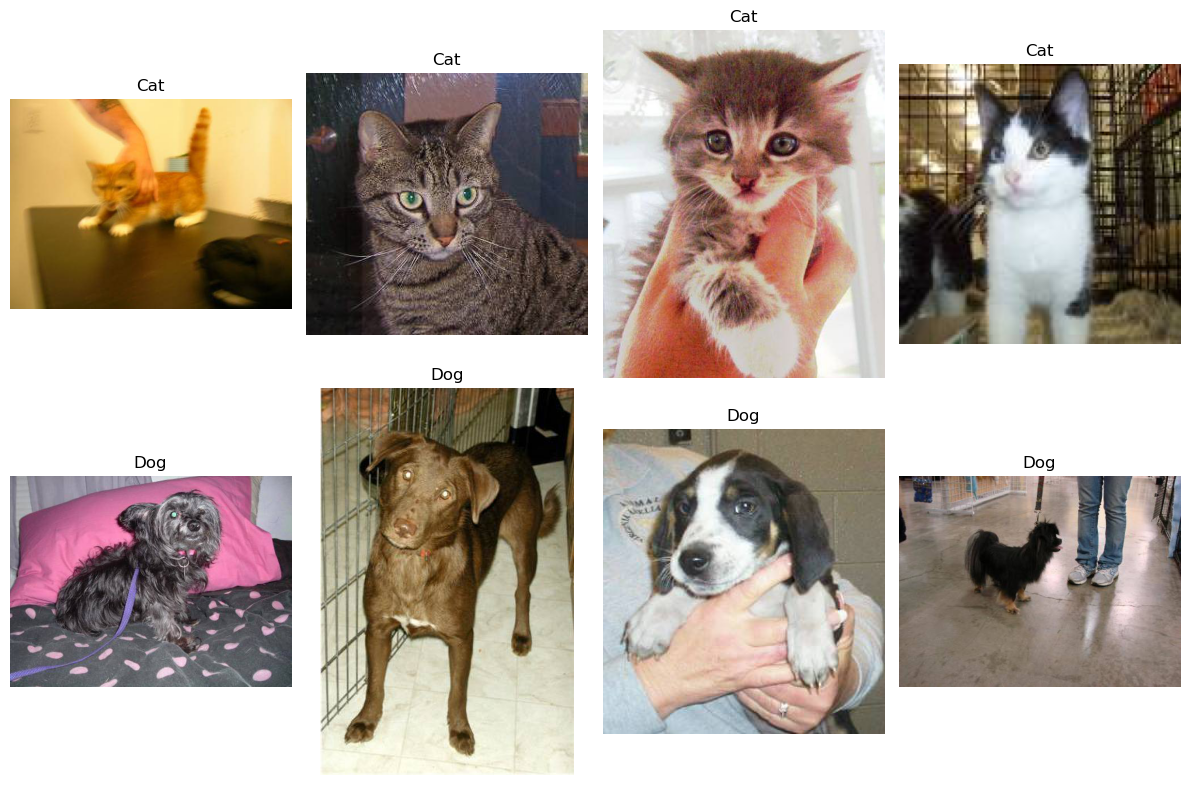

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(12, 8))

sample_cats = train_cats[:4]
sample_dogs = train_dogs[:4]


for i, img_name in enumerate(sample_cats):
    img_path = os.path.join(train_dir, "cats", img_name)

    img = Image.open(img_path)

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title("Cat")
    plt.axis("off")


for i, img_name in enumerate(sample_dogs):
    img_path = os.path.join(train_dir, "dogs", img_name)

    img = Image.open(img_path)

    plt.subplot(2, 4, i + 5)
    plt.imshow(img)
    plt.title("Dog")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
IMG_WIDTH = 150
IMG_HEIGHT = 150
BATCH_SIZE = 32

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

In [ ]:
val_datagen = ImageDataGenerator(
    rescale=1./255
)

In [ ]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_WIDTH, IMG_HEIGHT),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True
)

Found 20000 images belonging to 2 classes.


In [ ]:
val_generator = val_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_WIDTH, IMG_HEIGHT),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 5000 images belonging to 2 classes.


In [ ]:
images, labels = next(train_generator)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: (32, 150, 150, 3)
Label batch shape: (32,)


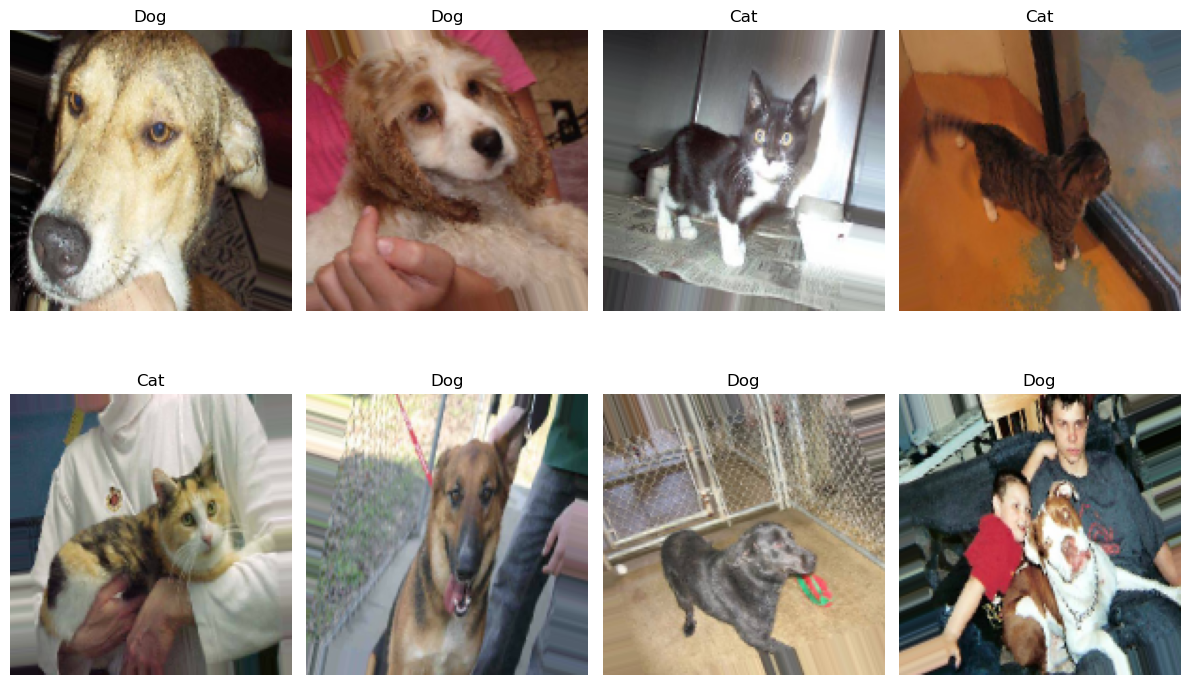

In [ ]:
plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i])

    label = "Dog" if labels[i] == 1 else "Cat"
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
model = Sequential([

    Conv2D(
        32,
        (3, 3),
        activation='relu',
        input_shape=(IMG_WIDTH, IMG_HEIGHT, 3)
    ),

    MaxPooling2D(2, 2),


    Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),

    MaxPooling2D(2, 2),


    Conv2D(
        128,
        (3, 3),
        activation='relu'
    ),

    MaxPooling2D(2, 2),


    Flatten(),


    Dense(
        512,
        activation='relu'
    ),


    Dropout(0.5),


    Dense(
        1,
        activation='sigmoid'
    )
])

C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([

    # Input layer
    Input(shape=(IMG_WIDTH, IMG_HEIGHT, 3)),

    # Convolution Layer 1
    Conv2D(
        32,
        (3, 3),
        activation='relu'
    ),

    MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Convolution Layer 2
    Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),

    MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Convolution Layer 3
    Conv2D(
        128,
        (3, 3),
        activation='relu'
    ),

    MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Fully Connected Layers
    Flatten(),

    Dense(
        512,
        activation='relu'
    ),

    Dropout(0.5),

    # Output Layer
    Dense(
        1,
        activation='sigmoid'
    )
])

print("CNN model created successfully.")

CNN model created successfully.


In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 72, 72, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 34, 34, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 17, 17, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 36992)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 512)                 │      18,940,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             513 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 19,034,177 (72.61 MB)

 Trainable params: 19,034,177 (72.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
checkpoint = ModelCheckpoint(
    "best_cats_dogs_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator,
    callbacks=[
        checkpoint,
        early_stopping
    ]
)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6130 - loss: 0.6603
Epoch 1: val_accuracy improved from None to 0.74440, saving model to best_cats_dogs_model.keras

Epoch 1: finished saving model to best_cats_dogs_model.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 826s 1s/step - accuracy: 0.6130 - loss: 0.6603 - val_accuracy: 0.7444 - val_loss: 0.5428
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7220 - loss: 0.5464
Epoch 2: val_accuracy improved from 0.74440 to 0.76980, saving model to best_cats_dogs_model.keras

Epoch 2: finished saving model to best_cats_dogs_model.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 703s 1s/step - accuracy: 0.7220 - loss: 0.5464 - val_accuracy: 0.7698 - val_loss: 0.4781
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 898ms/step - accuracy: 0.7682 - loss: 0.4853
Epoch 3: val_accuracy improved from 0.76980 to 0.81740, saving model to best_cats_dogs_model.keras

Epoch 3: finished saving model to best_cats_dogs_model.keras
625/625 ━━━━━━━━━━━━━━━━━━

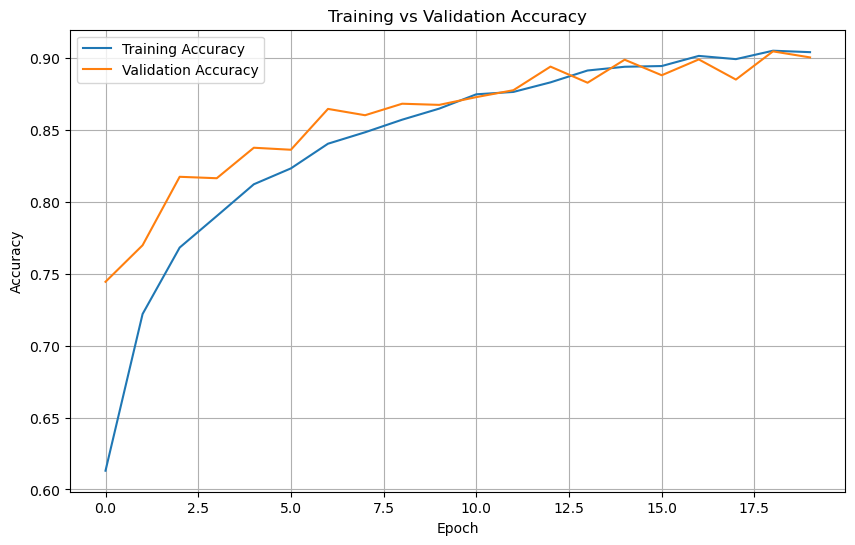

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

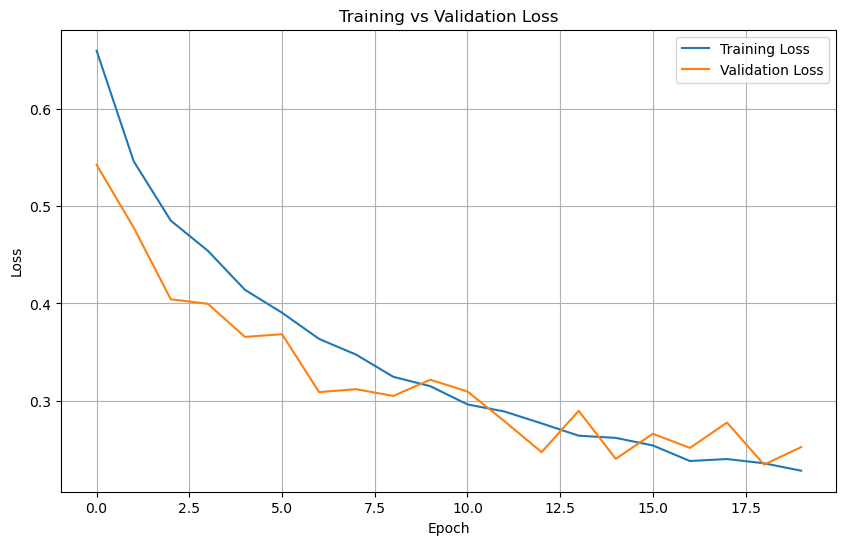

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
best_model = load_model(
    "best_cats_dogs_model.keras"
)

print("Best model loaded successfully.")

Best model loaded successfully.


In [ ]:
test_loss, test_accuracy = best_model.evaluate(
    val_generator
)

print("Validation Loss:", test_loss)
print("Validation Accuracy:", test_accuracy)

157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 211ms/step - accuracy: 0.9046 - loss: 0.2341
Validation Loss: 0.23406141996383667
Validation Accuracy: 0.9046000242233276


In [ ]:
val_generator.reset()

predictions = best_model.predict(val_generator)

predicted_classes = (predictions > 0.5).astype(int).flatten()

true_classes = val_generator.classes

157/157 ━━━━━━━━━━━━━━━━━━━━ 22s 140ms/step


In [ ]:
accuracy = accuracy_score(
    true_classes,
    predicted_classes
)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 90.46%


In [ ]:
precision = precision_score(
    true_classes,
    predicted_classes
)

print(f"Precision: {precision * 100:.2f}%")

Precision: 90.41%


In [ ]:
recall = recall_score(
    true_classes,
    predicted_classes
)

print(f"Recall: {recall * 100:.2f}%")

Recall: 90.52%


In [ ]:
f1 = f1_score(
    true_classes,
    predicted_classes
)

print(f"F1 Score: {f1 * 100:.2f}%")

F1 Score: 90.47%


In [ ]:
print(
    classification_report(
        true_classes,
        predicted_classes,
        target_names=['Cat', 'Dog']
    )
)

              precision    recall  f1-score   support

         Cat       0.91      0.90      0.90      2500
         Dog       0.90      0.91      0.90      2500

    accuracy                           0.90      5000
   macro avg       0.90      0.90      0.90      5000
weighted avg       0.90      0.90      0.90      5000



In [ ]:
cm = confusion_matrix(
    true_classes,
    predicted_classes
)

print(cm)

[[2260  240]
 [ 237 2263]]


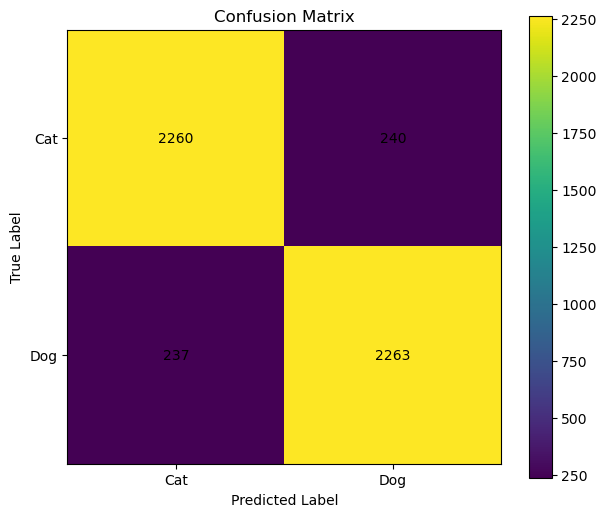

In [ ]:
plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0, 1],
    ['Cat', 'Dog']
)

plt.yticks(
    [0, 1],
    ['Cat', 'Dog']
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha='center',
            va='center'
        )

plt.colorbar()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step


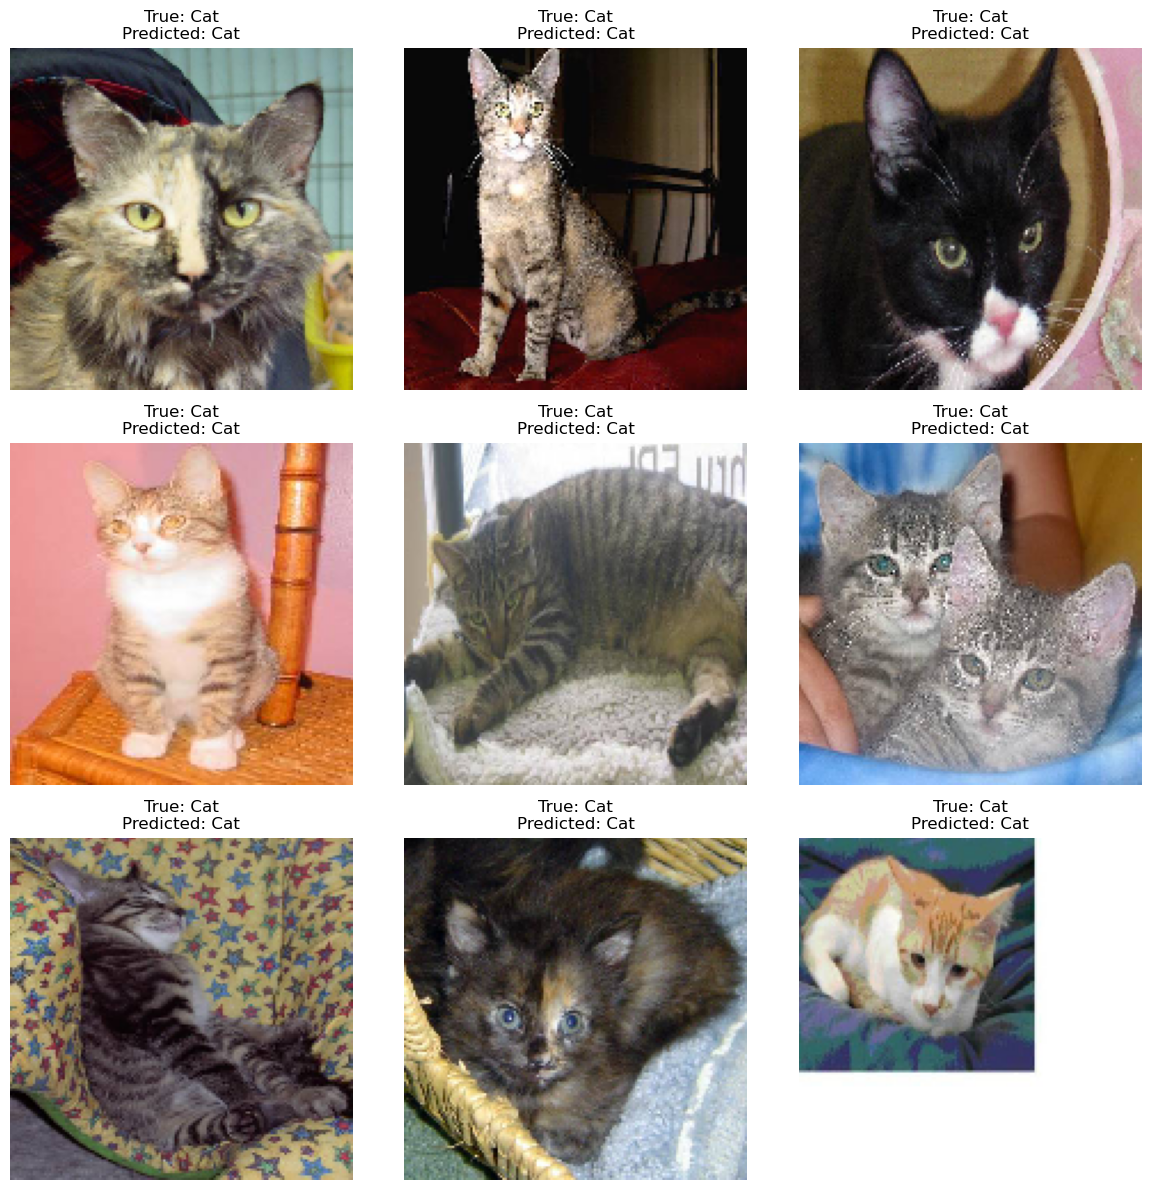

In [ ]:
val_generator.reset()

batch_images, batch_labels = next(val_generator)

batch_predictions = best_model.predict(batch_images)

batch_predicted_classes = (
    batch_predictions > 0.5
).astype(int).flatten()

plt.figure(figsize=(12, 12))

for i in range(9):

    plt.subplot(3, 3, i + 1)

    plt.imshow(batch_images[i])

    true_label = (
        "Dog" if batch_labels[i] == 1 else "Cat"
    )

    predicted_label = (
        "Dog"
        if batch_predicted_classes[i] == 1
        else "Cat"
    )

    if true_label == predicted_label:
        title = f"True: {true_label}\nPredicted: {predicted_label}"
    else:
        title = f"WRONG\nTrue: {true_label}\nPredicted: {predicted_label}"

    plt.title(title)

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
best_model.save(
    "cats_vs_dogs_classifier.keras"
)

print("Model saved successfully.")

Model saved successfully.


In [ ]:
loaded_model = load_model(
    "cats_vs_dogs_classifier.keras"
)

print("Model loaded successfully.")

Model loaded successfully.


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os

def predict_custom_image(image_path):


    if not os.path.isfile(image_path):
        print("ERROR: Image file not found.")
        print("Path:", image_path)
        return

    try:

        img = image.load_img(
            image_path,
            target_size=(IMG_WIDTH, IMG_HEIGHT)
        )


        img_array = image.img_to_array(img)


        img_array = img_array / 255.0

        img_array = np.expand_dims(
            img_array,
            axis=0
        )

        probability = loaded_model.predict(
            img_array,
            verbose=0
        )[0][0]

        if probability >= 0.5:
            prediction = "Dog"
            confidence = probability * 100
        else:
            prediction = "Cat"
            confidence = (1 - probability) * 100

        print("Prediction:", prediction)
        print(f"Confidence: {confidence:.2f}%")


        plt.figure(figsize=(6, 6))
        plt.imshow(img)
        plt.title(
            f"Prediction: {prediction}\n"
            f"Confidence: {confidence:.2f}%"
        )
        plt.axis("off")
        plt.show()

    except Exception as e:
        print("Unable to open/process the image.")
        print("Error:", e)



Enter the path of the cat/dog image:  C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\dogs\dog.232.jpg


Prediction: Dog
Probability/Confidence: 92.32%


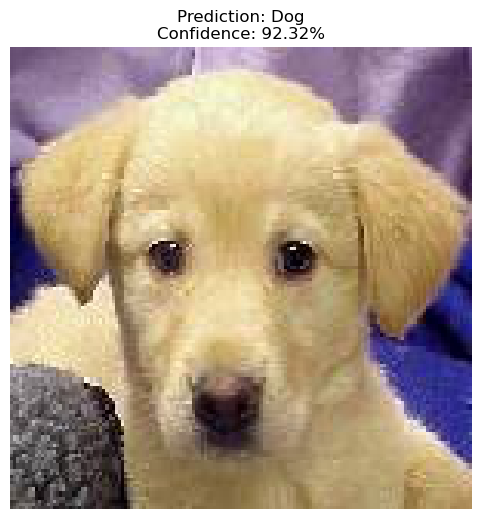

In [ ]:
image_path = input(
    "Enter the path of the cat/dog image: "
)

predict_custom_image(image_path)


Image: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\cats\cat.10.jpg
Prediction: Cat
Confidence: 100.00%


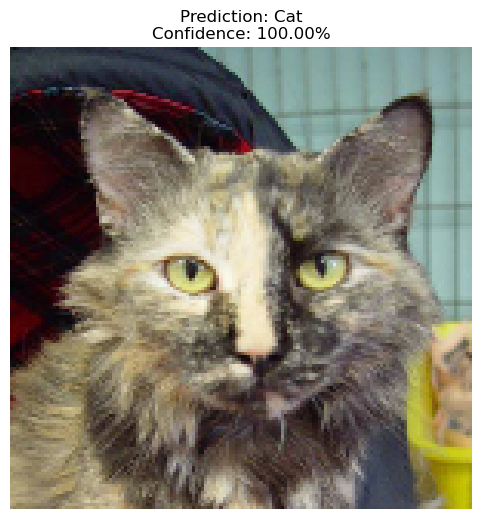


Image: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\dogs\dog.232.jpg
Prediction: Dog
Confidence: 92.32%


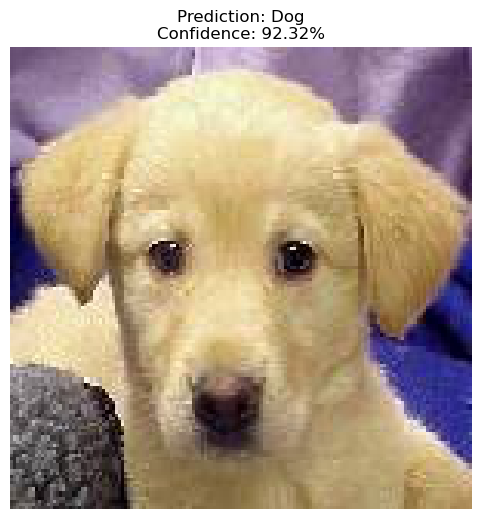


Image: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\cats\cat.151.jpg
Prediction: Cat
Confidence: 96.46%


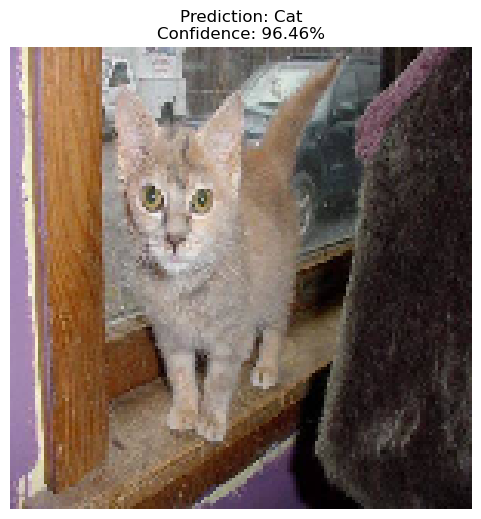


Image: C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\dogs\dog.775.jpg
Prediction: Dog
Confidence: 99.99%


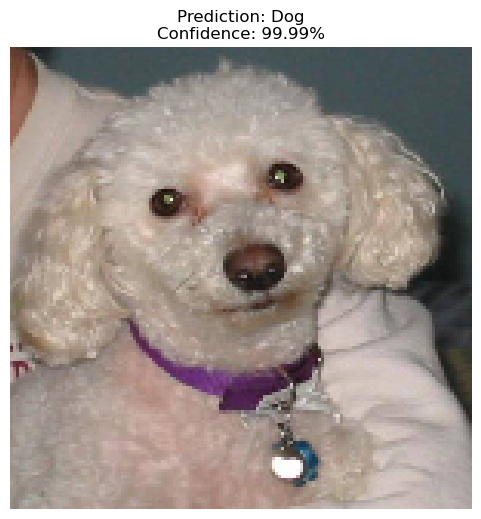


Image: C:\Users\hp\OneDrive\Pictures\Internship\premium_photo-1694819488591-a43907d1c5cc.avif
Unable to open/process the image.
Error: Failed to decode frame 0: No codec available


In [ ]:
custom_images = [
    r"C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\cats\cat.10.jpg",
    r"C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\dogs\dog.232.jpg",
    r"C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\cats\cat.151.jpg",
    r"C:\Users\hp\OneDrive\Pictures\Internship\Cats-Dogs\test\dogs\dog.775.jpg",
    r"C:\Users\hp\OneDrive\Pictures\Internship\premium_photo-1694819488591-a43907d1c5cc.avif"
]
for img_path in custom_images:

    print("\n" + "=" * 50)
    print("Image:", img_path)

    predict_custom_image(img_path)


Prediction: Cat
Confidence: 99.79%


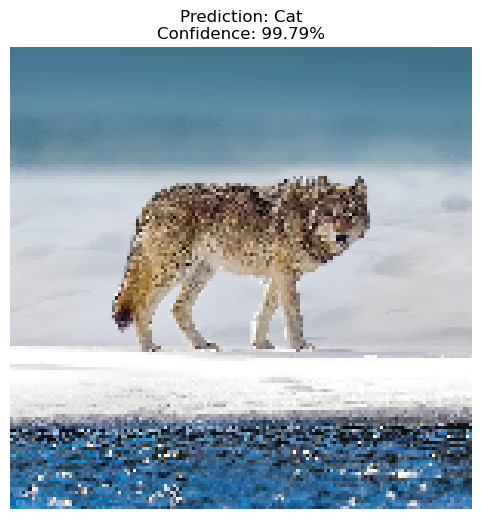

In [ ]:
edge_case = r"C:\Users\hp\OneDrive\Pictures\Internship\NAT-HAB-2027-wolf-image-1550w.webp"

predict_custom_image(edge_case)

In [ ]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]
})

results["Score"] = results["Score"].round(2)

print(results)

      Metric  Score
0   Accuracy  90.46
1  Precision  90.41
2     Recall  90.52
3   F1 Score  90.47
